# Study audit

Is the study complete and correct, what failed, and what did it cost? This notebook audits completeness, data integrity, failed attempts, run time and compute across all groups. It reports no scientific outcome. Every section reads a verified export, a local ledger or a local store, and prints a waiting line when its source is absent.

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
import pandas as pd
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()

from src.evaluation import study_audit
from src.visualize import audit as audit_figures
NOTEBOOK = "general/3_study_audit"
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope and provenance")
display_json("Notebook execution identity", provenance())

## What exists

Every result export the notebooks read, with its verification state. A superseded schema is identified but not read.

In [2]:
report_section("2. Result exports")
exports = study_audit.export_status()
frames = exports.attrs["frames"]
display_table("Result exports", exports, preview_rows=12)

study,notebook,status,schema,created_utc,export,note
A1,A/A1,superseded_schema,jevpfn.rq1a.report.v1,2026-11-18T13:24:39.664228+00:00,A/A1/results/outputs/comparison.zip,jevpfn.rq1a.report.v2
A2,A/A2,awaiting_export,None,None,A/A2/results/robustness/robustness.open_weight-5baeccd37d70d034.zip,None
A3,A/A3,awaiting_export,None,None,A/A3/results/geometry/open_weight-5baeccd37d70d034/geometry.zip,None
B1,B/B1,awaiting_export,None,None,B/B1/results/group_b/b1_decision_features.open_weight-5baeccd37d70d034.zip,None
B2,B/B2,awaiting_export,None,None,B/B2/results/group_b/b2_frozen_embeddings.open_weight-5baeccd37d70d034.zip,None
B3,B/B3,awaiting_export,None,None,B/B3/results/group_b/b3_label_trained.open_weight-5baeccd37d70d034.zip,None
B4,B/B4,awaiting_export,None,None,B/B4/results/group_b/b4_when_text_helps.open_weight-5baeccd37d70d034.zip,None
B5,B/B5,awaiting_export,None,None,B/B5/results/group_b/b5_data_efficiency.open_weight-5baeccd37d70d034.zip,None
B6,B/B6,awaiting_export,None,None,B/B6/results/group_b/b6_native_text.open_weight-5baeccd37d70d034.zip,None
C1,C/C1,awaiting_export,None,None,C/C1/results/group_c/c1_representations.zip,None


## Completeness

Feature stores (available now; the figure is in `general/2_feature_creation`) and every planned benchmark arm per study, arm family, dataset and predictor: complete, a roster gap (whole decision models missing), incomplete, or not planned by design.

In [3]:
report_section("3. Completeness")
from src.evaluation.campaign import benchmark_plan
from src.evaluation.benchmark_export import cohort_name, decision_roster
spend = study_audit.jev_spend()
store = study_audit.feature_store_status(partial={("jev", d) for d in spend.dataset_id})
display_table("Decision-feature store views per status", store.groupby(["status"]).size().rename("dataset_model_views").reset_index())
plan = pd.DataFrame(benchmark_plan(cohort=cohort_name()))
from src.utils.config import load_yaml
tasks = {d: s["task_type"] for d, s in load_yaml("dataset_semantics")["datasets"].items()}
plan["task_type"] = plan.dataset_id.map(tasks)
exported = [frames[s]["folds"] for s in ("B1", "B2", "B3", "B4", "B5", "B6", "C1", "C2") if frames.get(s) and "folds" in frames[s]]
if exported:
    folds = pd.concat(exported, ignore_index=True)
    arms = study_audit.arm_completeness(folds, plan[plan.phase.isin(set(folds.phase.astype(str)))], roster=decision_roster())
    display_table("Arm completeness", arms.groupby(["study", "family", "status"]).size().rename("cells").reset_index(), preview_rows=20)
    fig, name, caption = audit_figures.completeness_figure(arms)
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
else:
    print("Waiting for export: no Group B or C export exists locally, so arm completeness cannot be audited yet.")

status,dataset_model_views
observed,520
partial,34
unknown,58


Waiting for export: no Group B or C export exists locally, so arm completeness cannot be audited yet.


## Data checks

Per export: duplicate fold records, non-finite headline values and arms without exactly five folds.

In [4]:
report_section("4. Data checks")
checks = [study_audit.fold_checks(frames[s]["folds"], s) for s in ("B1", "B2", "B3", "B4", "B5", "B6", "C1", "C2") if frames.get(s) and "folds" in frames[s]]
if checks:
    display_table("Fold-table checks", pd.DataFrame(checks))
else:
    print("Waiting for export: no fold tables to check.")

Waiting for export: no fold tables to check.


## Failed attempts

Terminal Slurm attempts per stage from the compute ledger (`python -m src.cluster.compute_ledger` on VSC, copied to `output_JEVPFN/compute_ledger.json`). Failed, cancelled and timed-out jobs stay part of the record.

stage,state,jobs,gpu_hours,cpu_core_hours
decision_feature_creation,CANCELLED,35,1.520833,30.349444
decision_feature_creation,COMPLETED,378,505.646111,5522.779167
decision_feature_creation,FAILED,84,85.834722,1174.086389
decision_feature_creation,TIMEOUT,3,0.000000,24.028889
fold_pca,COMPLETED,54,0.000000,21.615556
frozen_embedding_creation,COMPLETED,59,8.752500,70.254444
frozen_embedding_creation,FAILED,1,0.000000,0.024444
infrastructure,CANCELLED,5,0.000000,12.130000
infrastructure,COMPLETED,47,0.949167,45.898056
infrastructure,FAILED,20,0.000000,5.211111


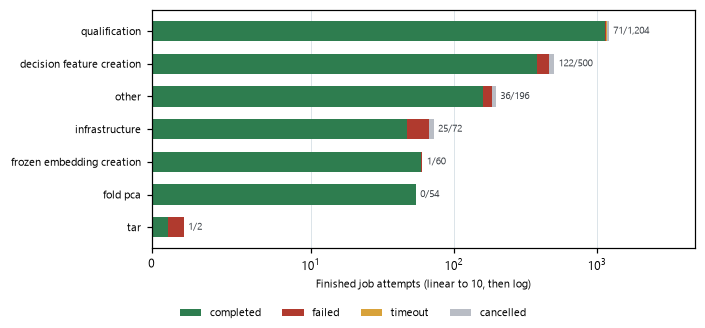

In [5]:
report_section("5. Failed attempts")
ledger = study_audit.read_compute_ledger()
jobs, by_study = study_audit.ledger_tables(ledger)
if jobs.empty:
    print("Waiting for the compute ledger: output_JEVPFN/compute_ledger.json is not held locally.")
else:
    register = study_audit.failure_register(jobs)
    display_table("Failure register", register, preview_rows=20)
    fig, name, caption = audit_figures.failure_register_figure(register)
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

## Run time

Mean outer-fold fit seconds against input columns per predictor, from the export fold tables (`seconds.fit`, `columns.representation`).

In [6]:
report_section("6. Run time")
fits = pd.concat([study_audit.fit_seconds(f) for f in exported], ignore_index=True) if exported else pd.DataFrame()
if fits.empty:
    print("Waiting for export: no fit timings are available.")
else:
    display_table("Fit seconds per predictor and family", fits.groupby(["model_id", "family"]).fit_seconds.describe().reset_index(), preview_rows=14)
    fig, name, caption = audit_figures.runtime_figure(fits)
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

Waiting for export: no fit timings are available.


## Compute and spending

The ledger records allocated GPU-hours and CPU core-hours by study, including failed jobs. The table lists Jev charges, reservations and allocations in USD. The cumulative spending ceiling is USD 5.50.

dataset_id,jobs,completed,unresolved,spent_usd,reserved_usd,allocation_usd
BIN_TEXT_FAKE_JOB_POSTING,9596,9595,1,0.286938,0.000000,0.305555
BIN_TEXT_JIGSAW_TOXICITY,12059,12058,1,0.289664,0.000000,0.305555
BIN_TEXT_KICKSTARTER_FUNDING,12504,12503,1,0.289042,0.000000,0.305555
MUL_TEXT_DATA_SCIENTIST_SALARY,7416,7415,1,0.292064,0.000000,0.305555
MUL_TEXT_MICHELIN_RESTAURANTS,7891,7890,1,0.289683,0.000000,0.305555
MUL_TEXT_PRODUCT_SENTIMENT,5088,5088,0,0.144895,0.000000,0.305555
MUL_TEXT_US_ACCIDENTS,9601,9600,1,0.291398,0.000000,0.305555
MUL_TEXT_WINE_REVIEW,3701,3700,1,0.288533,0.000000,0.305555
MUL_TEXT_WOMEN_CLOTHING_REVIEW,9084,9083,1,0.284291,0.000000,0.305555
REG_TEXT_BABIES_PRICES,9395,9394,1,0.285378,0.000000,0.305555


study,jobs,successful_jobs,gpu_hours,successful_gpu_hours,cpu_core_hours,successful_cpu_core_hours
0 and B0 qualification,1204.0,1133.0,16.74,6.13,1444.52,917.00
B2 frozen embeddings,54.0,54.0,0.00,0.00,21.62,21.62
B3 TAR,2.0,1.0,0.32,0.31,2.57,2.47
Feature creation,560.0,437.0,601.75,514.40,6821.52,5593.03
Infrastructure,72.0,47.0,0.95,0.95,63.24,45.90
Other,196.0,160.0,1.31,1.26,110.15,85.34


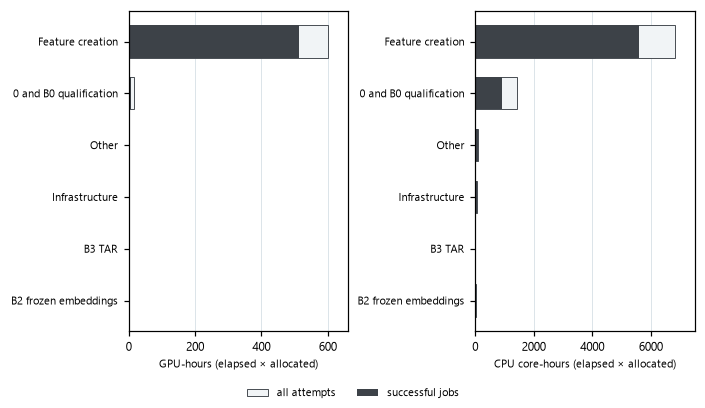

In [7]:
report_section("7. Compute and spending")
budget = study_audit.jev_budget(spend)
display_json("Jev charges against the ceiling", budget)
if not spend.empty:
    display_table("Jev spending by dataset (USD)", spend, preview_rows=len(spend))
if not by_study.empty:
    display_table("Compute per study", by_study.round(2), preview_rows=14)
else:
    print("Waiting for the compute ledger: GPU and CPU hours per study are not available locally.")
panel = audit_figures.compute_figure(by_study)
if panel is not None:
    fig, name, caption = panel
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

## C0 qualification and Group C diagnostics

C0 exercises each of three Strands v1 training configurations on one dataset per task type. The table shows which pilot receipts are available here and their measured speed and peak GPU memory. Production C2 also verifies each bundle and its signed review on VSC. C1 checks whether its saved vectors reproduce the released model’s probabilities. C2 reports diagnostics for every production fit.

In [8]:
report_section("8. C0 qualification and Group C diagnostics")
display_table("C0 Strands v1 training pilots", study_audit.strands_qualification(), preview_rows=9)
from src.evaluation import group_c_views
c1, c2 = frames.get("C1") or {}, frames.get("C2") or {}
if "extraction" in c1:
    display_table("C1 head-reproduction contract", group_c_views.head_reproduction_contract(c1["extraction"]), preview_rows=18)
else:
    print("Waiting for export: C1 head-reproduction contract (c1_representations.zip).")
if "fits" in c2:
    display_table("C2 fit diagnostics", group_c_views.fit_diagnostics(c2["fits"], by=("cell",)))
    display_json("C2 training GPU-hours", group_c_views.training_gpu_hours(c2["fits"]))
else:
    print("Waiting for export: C2 fit diagnostics (c2_adaptation.zip).")

task,dataset,training configuration,local receipt,training examples/s,peak GPU GiB
binary_classification,BIN_TEXT_FAKE_JOB_POSTING,head_only,pending,None,None
binary_classification,BIN_TEXT_FAKE_JOB_POSTING,lora_only,pending,None,None
binary_classification,BIN_TEXT_FAKE_JOB_POSTING,lora_head,pending,None,None
multiclass_classification,MUL_TEXT_PRODUCT_SENTIMENT,head_only,pending,None,None
multiclass_classification,MUL_TEXT_PRODUCT_SENTIMENT,lora_only,pending,None,None
multiclass_classification,MUL_TEXT_PRODUCT_SENTIMENT,lora_head,pending,None,None
regression,REG_TEXT_BOOK_READABILITY,head_only,pending,None,None
regression,REG_TEXT_BOOK_READABILITY,lora_only,pending,None,None
regression,REG_TEXT_BOOK_READABILITY,lora_head,pending,None,None


Waiting for export: C1 head-reproduction contract (c1_representations.zip).
Waiting for export: C2 fit diagnostics (c2_adaptation.zip).


## Complete report

In [9]:
finish_report(NOTEBOOK, save.summary() + "\nOnly verified exports, local ledgers and stores were read; no inference, model training or live VSC changes were performed.")

general/3_study_audit

1. Scope and provenance


Notebook execution identity
{
  "code_sha256": "253d5f17bdea4be35b0e853055326f9a06bd5d0a5b2b0c789f83d236fd3c5074",
  "git_head": "0929454751c9921410a46b29506eb6c2b4ca280f",
  "git_dirty": true,
  "tfm_library_pin": "4574eea0c2ce6646b5d2e9c7f53a6ef3882c368c dm-library (remotes/origin/HEAD)\n 248f137046487e0d57360abba1e060420ae54e1a tfm-library (remotes/origin/HEAD)\n 2208cf68d6351eff2cb0ddb5a9eb1d822523457b vsc-library (heads/main-8-g2208cf6)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.4",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


2. Result exports


Result exports
study notebook            status                schema                      created_utc                                                                     export                  note
   A1     A/A1 superseded_schema jevpfn.rq1a.report.v1 2026-11-18T13:24:39.664228+00:00                        